# Hessian estimation from regression-tree splits: 3D OPFData study

**Objective.** Estimate how the cost of meeting electricity demand changes jointly with 3 selected demand inputs. Compare a Hessian reconstructed from CART split information with a residual-based Principal Hessian Directions (PHD) estimate.

**Data.** IEEE-118 OPFData subset, 5,000 records. The current CSV convention is column 0 for optimal cost and columns 1, 2, 3 for selected demands. This convention must be checked against the dataset extraction script before physical interpretation.

**Scope.** The two matrices are separate estimates, not ground truth. The immediate checks are whether the CART equations identify every row, whether the raw result is symmetric, and how the two estimates differ. Eigenanalysis and physical interpretation are outside this first attempt.

## Data and experimental configuration

All observations are retained. The comparison uses the original values in the CSV, without standardizing or transforming predictors or response. The full 2 GB dataset is not loaded.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.tree import DecisionTreeRegressor

CSV_PATH = Path(r"/Users/tonys/Desktop/Class/Decision Trees/datasets/118_ieee_smol.csv")
TARGET_COLUMN = 0
FEATURE_COLUMNS = [1, 2, 3]
TREE_MAX_DEPTH = 7
TREE_RANDOM_STATE = 0

np.set_printoptions(precision=4, suppress=True, linewidth=110)
print(f"Python {sys.version.split()[0]}  |  NumPy {np.__version__}  |  pandas {pd.__version__}")

Python 3.13.5  |  NumPy 2.3.5  |  pandas 2.2.3


In [2]:
def load_opfdata(csv_path: Path, target_column: int, feature_columns: list[int]):
    """Load selected numeric columns from a headerless OPFData CSV.

    Args:
        csv_path: Preferred input CSV path.
        target_column: Zero-based column holding the response.
        feature_columns: Zero-based predictor columns, in desired order.

    Returns:
        X: Predictor matrix, shape (n, d).
        y: Response vector, shape (n,).
        used_path: Actual file path used for loading.
    """
    candidates = [csv_path, Path("118_ieee_smol.csv"),
                  Path("/mnt/data/118_ieee_smol.csv")]
    used_path = next((p for p in candidates if p.is_file()), None)
    if used_path is None:
        raise FileNotFoundError(f"No input CSV found at: {candidates}")
    if len(set(feature_columns)) != len(feature_columns) or target_column in feature_columns:
        raise ValueError("Predictors must be unique and exclude the response column.")
    frame = pd.read_csv(used_path, header=None)
    cols = [target_column] + feature_columns
    if min(cols) < 0 or max(cols) >= frame.shape[1]:
        raise ValueError(f"Columns {cols} fall outside CSV width {frame.shape[1]}")
    arr = frame.iloc[:, cols].to_numpy(dtype=float)
    if not np.isfinite(arr).all():
        raise ValueError("Selected inputs contain missing or infinite values")
    y, X = arr[:, 0], arr[:, 1:]
    if (X.max(axis=0) <= X.min(axis=0)).any():
        raise ValueError("At least one predictor has no variation")
    return X, y, used_path


X, y, used_path = load_opfdata(CSV_PATH, TARGET_COLUMN, FEATURE_COLUMNS)
summary = pd.DataFrame({
    "Input": ["Cost (response)"] + [f"Demand {j}" for j in FEATURE_COLUMNS],
    "CSV column": [TARGET_COLUMN] + FEATURE_COLUMNS,
    "Minimum": [y.min()] + [X[:,i].min() for i in range(X.shape[1])],
    "Maximum": [y.max()] + [X[:,i].max() for i in range(X.shape[1])],
})
print(f"Loaded {len(y):,} observations from {used_path.name}; {X.shape[1]} selected demand variables.")
display(summary.style.format({"Minimum": "{:,.4f}", "Maximum": "{:,.4f}"}))

Loaded 5,000 observations from 118_ieee_smol.csv; 3 selected demand variables.


,Input,CSV column,Minimum,Maximum
0,Cost (response),0,"69,269.8984","124,285.5312"
1,Demand 1,1,0.3294,0.7332
2,Demand 2,2,0.1297,0.2868
3,Demand 3,3,0.2536,0.5568


## PHD: estimating curvature from observed data

**Principal Hessian Directions (PHD)** is a statistical method for detecting curved relationships between inputs and responses. It does not fit a regression tree or differentiate observations individually. Instead, it examines patterns in the response that a straight-line relationship cannot explain.

First, fit an ordinary linear regression relating the selected electricity demands to operating cost. A **residual** is the observed cost minus the cost predicted by this straight-line model. If the cost relationship bends, residuals may be systematically associated with squared demands or with products of different demands.

The residual-based PHD calculation combines three quantities: the centered demand vectors, the linear-regression residuals, and the predictor covariance matrix (which accounts for different scales and correlations). Written mathematically,

\[
\widehat H_{\mathrm{PHD}}
=
\widehat\Sigma^{-1}
\left(\frac{1}{n}\sum_{i=1}^{n}r_i z_i z_i^\top\right)
\widehat\Sigma^{-1},
\qquad z_i=x_i-\bar x,\quad r_i=y_i-\widehat y_i.
\]

The middle term measures how unexplained cost variation is associated with pairs of demand variables. The covariance factors translate that relationship into the original demand coordinates. Under classical Gaussian-predictor assumptions and suitable smoothness conditions, the population quantity corresponds to the **average Hessian of the regression function**. Here it is a **baseline estimate**, not ground truth.

**Implementation.** The function **estimate_phd(X, y)** fits a linear model, calculates residuals, constructs the residual-weighted matrix and input covariance, and solves the matrix equations. It returns the symmetric PHD estimate and the covariance condition number. It does not train a second model after linear regression or re-solve any AC optimal-power-flow problems.

The numerical matrix is displayed below. Eigenvalues and eigenvectors are intentionally deferred.

In [3]:
def estimate_phd(X: np.ndarray, y: np.ndarray):
    """Calculate the classical residual-based PHD matrix in CSV input units.

    Args:
        X: Demand measurements of shape (n, d).
        y: Corresponding cost observations of shape (n,).

    Returns:
        hessian: Symmetric residual-based PHD estimate of shape (d, d).
        condition: Condition number of the empirical predictor covariance.
    """
    n = X.shape[0]
    centered = X - X.mean(axis=0)
    design = np.column_stack((np.ones(n), centered))
    coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
    residual = y - design @ coefficients
    covariance = centered.T @ centered / n
    condition = float(np.linalg.cond(covariance))
    if not np.isfinite(condition) or condition > 1e12:
        raise ValueError(f"Predictor covariance is ill-conditioned: {condition:.3g}")
    moment = centered.T @ (residual[:, None] * centered) / n
    # For Gaussian predictors, this is an average-Hessian identity.
    hessian = np.linalg.solve(covariance, moment)
    hessian = np.linalg.solve(covariance, hessian.T).T
    return (hessian + hessian.T) / 2, condition


H_phd, phd_cov_condition = estimate_phd(X, y)
print(f"PHD covariance condition number: {phd_cov_condition:.3f}")
print("PHD matrix (original units):\n", H_phd)

PHD covariance condition number: 12.894
PHD matrix (original units):
 [[ 152100.9243 -232667.5294 -106877.3764]
 [-232667.5294  956292.5019 -353929.2345]
 [-106877.3764 -353929.2345  249668.2794]]


## Tree-based Hessian reconstruction: estimating curvature from splits

A CART regression tree partitions the demand space into regions. At each internal node, it selects a demand variable and threshold to reduce squared prediction error. The observations on each side of a split supply **two mean operating costs**.

A tree predicts a constant inside each terminal region. Directly differentiating those predictions gives zero almost everywhere, so **that is not the approach used here**. Instead, the method uses the contrast between the means of the two children.

For a node splitting demand variable \(s\),

\[
\gamma_s=\frac{2(\bar y_R-\bar y_L)}{u_s-\ell_s},
\]

where \(\bar y_L\) and \(\bar y_R\) are the observed left/right child costs and \([\ell_s,u_s]\) is the parent region's extent along the splitting variable. The numerator measures the change between the two sides; the denominator accounts for the region's width.

To obtain second-order information, the algorithm compares these derivative-like values at **different locations**. It computes an effective location from each node's bounds and split threshold. Nodes splitting the same variable are collected, their effective locations and contrasts are compared, and a least-squares system estimates **one Hessian row**. Repeating this for each selected demand constructs the raw matrix.

**Implementation.** The function **collect_splits** extracts each internal CART split, bounds, threshold, and both child response means. **estimate_tree_hessian** constructs the contrasts and effective locations, solves the row-wise linear systems, and reports the node counts, rank, and condition number. The resulting matrix is displayed **without symmetrization**; opposing entries are inspected numerically in the following section.

**Limitations.** The effective-location identity is exact in the quadratic construction under its regional-averaging assumptions. Those conditions are not guaranteed for correlated or nonuniform OPFData demands, and the real cost response need not have a constant Hessian. Full rank establishes that the equation system is identifiable, **not** that the estimated Hessian is accurate.

In [4]:
@dataclass
class SplitRecord:
    """Information from one CART internal split.

    Args:
        feature: Splitting variable, zero-based among selected predictors.
        lower, upper: Boundaries of the split's rectangular region.
        threshold: Split value in the selected variable.
        mean_left, mean_right: Observed child-node response means.
    """
    feature: int
    lower: np.ndarray
    upper: np.ndarray
    threshold: float
    mean_left: float
    mean_right: float


def collect_splits(regressor, lower: np.ndarray, upper: np.ndarray):
    """Extract the internal splits and child-node means from a fitted CART tree.

    Args:
        regressor: Fitted sklearn DecisionTreeRegressor.
        lower, upper: Assumed outer domain bounds for the selected inputs.

    Returns:
        List of SplitRecord objects, one per internal tree node.
    """
    t = regressor.tree_
    stack = [(0, np.asarray(lower, float).copy(), np.asarray(upper, float).copy())]
    records = []
    while stack:
        node_id, lo, hi = stack.pop()
        left = int(t.children_left[node_id])
        if left == -1:
            continue
        right = int(t.children_right[node_id])
        feature = int(t.feature[node_id])
        threshold = float(t.threshold[node_id])
        if not (lo[feature] < threshold < hi[feature]):
            raise ValueError(f"Node {node_id}: split is outside its recorded region")
        records.append(SplitRecord(
            feature=feature, lower=lo.copy(), upper=hi.copy(), threshold=threshold,
            mean_left=float(t.value[left].ravel()[0]),
            mean_right=float(t.value[right].ravel()[0])
        ))
        left_hi = hi.copy(); left_hi[feature] = threshold
        right_lo = lo.copy(); right_lo[feature] = threshold
        stack.append((left, lo.copy(), left_hi))
        stack.append((right, right_lo, hi.copy()))
    return records


def estimate_tree_hessian(records: list[SplitRecord], dimension: int):
    """Estimate Hessian rows from CART derivative contrasts and effective centers.

    Args:
        records: Internal CART splits with bounds and response means.
        dimension: Number of selected demand variables.

    Returns:
        raw: Asymmetric, unsymmetrized Hessian estimate (d by d).
        diagnostics: DataFrame of split counts, row rank and conditioning.
    """
    raw = np.full((dimension, dimension), np.nan)
    diagnostics = []
    for s in range(dimension):
        chosen = [r for r in records if r.feature == s]
        if len(chosen) < dimension + 1:
            diagnostics.append((s + 1, len(chosen), 0, np.inf))
            continue
        centers = np.array([(r.lower + r.upper) / 2 for r in chosen])
        contrasts = np.array([
            2 * (r.mean_right - r.mean_left) / (r.upper[s] - r.lower[s])
            for r in chosen
        ])
        for k, r in enumerate(chosen):
            centers[k, s] = (r.lower[s] + r.threshold + r.upper[s]) / 3
        centered_centers = centers - centers.mean(axis=0)
        centered_contrasts = contrasts - contrasts.mean()
        estimate, _, rank, sv = np.linalg.lstsq(
            centered_centers, centered_contrasts, rcond=1e-10)
        condition = float(sv[0] / sv[-1]) if rank == dimension and sv[-1] > 0 else np.inf
        if rank == dimension:
            raw[s] = estimate
        diagnostics.append((s + 1, len(chosen), int(rank), condition))
    return raw, pd.DataFrame(diagnostics, columns=[
        "Demand", "Nodes splitting variable", "Rank", "Condition number"])


regressor = DecisionTreeRegressor(
    max_depth=TREE_MAX_DEPTH, random_state=TREE_RANDOM_STATE
).fit(X, y)

# Dataset extrema are provisional bounds; OPFData does not provide true box boundaries in the CSV.
records = collect_splits(regressor, X.min(axis=0), X.max(axis=0))
H_tree_raw, row_checks = estimate_tree_hessian(records, dimension=X.shape[1])
print(f"CART depth: {regressor.get_depth()}  |  internal splits: {len(records)}")
display(row_checks.style.format({"Condition number": "{:.2f}"}))
print("Tree-based Hessian BEFORE symmetrization:\n", H_tree_raw)

CART depth: 7  |  internal splits: 124


,Demand,Nodes splitting variable,Rank,Condition number
0,1,44,3,3.03
1,2,41,3,2.51
2,3,39,3,2.99


Tree-based Hessian BEFORE symmetrization:
 [[ -399605.6395  1153309.0293  1158807.5493]
 [-1022674.0397 -1601111.0082   120826.4996]
 [  777750.4655 -2121290.0764   315482.3951]]


## Numerical symmetry check

For a twice continuously differentiable function, the Hessian is symmetric. We inspect each distinct off-diagonal pair **before any adjustment**: the two independent estimates, their signed difference, and the size of that difference. The mean, median, and maximum are summaries *across these pairs*, not across observations. In 2D there is only one pair; in 3D there are three.

In [5]:
def off_diagonal_checks(matrix: np.ndarray):
    """List the numerical disagreement between opposing Hessian entries.

    Args:
        matrix: Raw, unsymmetrized square Hessian estimate.

    Returns:
        pairs: Table with each H[i,j], H[j,i], and their differences.
        summary: One-row table of mean, median, and maximum absolute gaps.
    """
    if not np.isfinite(matrix).all():
        raise ValueError("At least one Hessian row is unidentified; cannot check all pairs")
    n = matrix.shape[0]
    rows = []
    for i in range(n):
        for j in range(i + 1, n):
            delta = float(matrix[i, j] - matrix[j, i])
            rows.append({
                "Pair": f"({i+1}, {j+1})",
                "H[i,j]": matrix[i, j],
                "H[j,i]": matrix[j, i],
                "Signed gap": delta,
                "Absolute gap": abs(delta),
            })
    pairs = pd.DataFrame(rows)
    gaps = pairs["Absolute gap"].to_numpy()
    summary = pd.DataFrame([{
        "Distinct pairs": len(gaps),
        "Mean absolute gap": np.mean(gaps),
        "Median absolute gap": np.median(gaps),
        "Maximum absolute gap": np.max(gaps),
    }])
    return pairs, summary


pair_table, symmetry_summary = off_diagonal_checks(H_tree_raw)
print("Raw CART Hessian: opposing entries compared numerically")
display(pair_table.style.format({
    "H[i,j]": "{:,.2f}", "H[j,i]": "{:,.2f}",
    "Signed gap": "{:+,.2f}", "Absolute gap": "{:,.2f}"
}))
display(symmetry_summary.style.format({
    "Mean absolute gap": "{:,.2f}",
    "Median absolute gap": "{:,.2f}",
    "Maximum absolute gap": "{:,.2f}",
}))

Raw CART Hessian: opposing entries compared numerically


,Pair,"H[i,j]","H[j,i]",Signed gap,Absolute gap
0,"(1, 2)","1,153,309.03","-1,022,674.04","+2,175,983.07","2,175,983.07"
1,"(1, 3)","1,158,807.55","777,750.47","+381,057.08","381,057.08"
2,"(2, 3)","120,826.50","-2,121,290.08","+2,242,116.58","2,242,116.58"


,Distinct pairs,Mean absolute gap,Median absolute gap,Maximum absolute gap
0,3,"1,599,718.91","2,175,983.07","2,242,116.58"


## Estimated matrices and disagreement

Figures show each estimated Hessian directly. Color indicates sign and magnitude; annotations show numbers in **millions of cost units per squared demand unit** to keep labels readable. The CART figure is intentionally **not symmetrized**. Any difference between the two methods is disagreement, not error relative to a true Hessian.

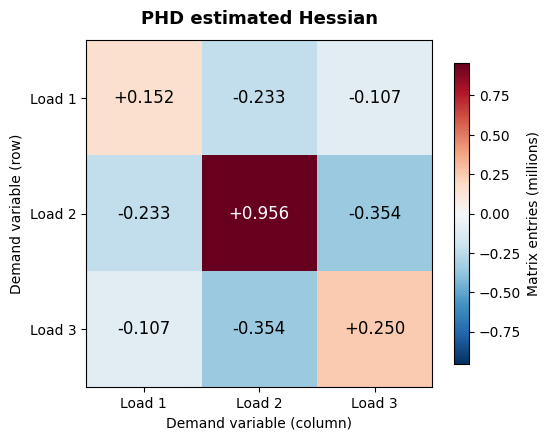

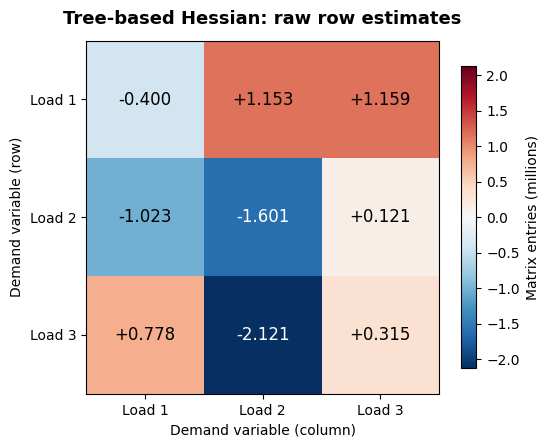

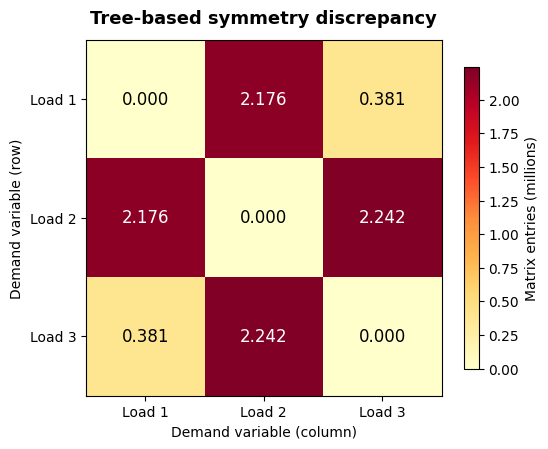

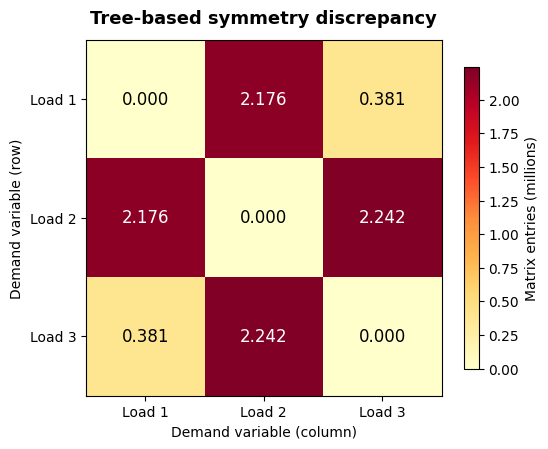

In [6]:
def plot_hessian(matrix: np.ndarray, title: str, *, absolute: bool = False):
    """Display one annotated Hessian matrix on a common readable scale.

    Args:
        matrix: Square matrix to plot.
        title: Figure title identifying estimator or diagnostic.
        absolute: Whether to use a nonnegative color scale.

    Returns:
        Matplotlib figure displayed in the notebook.
    """
    values = np.asarray(matrix, dtype=float) / 1e6
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    if absolute:
        image = ax.imshow(values, cmap="YlOrRd", vmin=0)
    else:
        vmax = max(0.1, float(np.abs(values).max()))
        image = ax.imshow(values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            color = "white" if abs(values[i,j]) > 0.60 * max(np.abs(values).max(), 1e-12) else "black"
            ax.text(j, i, f"{values[i,j]:+.3f}" if not absolute else f"{values[i,j]:.3f}",
                    ha="center", va="center", fontsize=12, weight="medium", color=color)
    ticks = np.arange(matrix.shape[0])
    ax.set_xticks(ticks, [f"Load {j+1}" for j in ticks])
    ax.set_yticks(ticks, [f"Load {j+1}" for j in ticks])
    ax.set_xlabel("Demand variable (column)")
    ax.set_ylabel("Demand variable (row)")
    ax.set_title(title, fontsize=13, weight="bold", pad=12)
    fig.colorbar(image, ax=ax, shrink=.83, label="Matrix entries (millions)")
    fig.tight_layout()
    plt.show()
    return fig


plot_hessian(H_phd, "PHD estimated Hessian")
plot_hessian(H_tree_raw, "Tree-based Hessian: raw row estimates")
plot_hessian(np.abs(H_tree_raw - H_tree_raw.T),
             "Tree-based symmetry discrepancy", absolute=True)

In [7]:
comparison = np.abs(H_tree_raw - H_phd)
print("PHD vs raw CART absolute entrywise differences (no known true Hessian):")
display(pd.DataFrame(comparison,
                     index=[f"Load {j}" for j in FEATURE_COLUMNS],
                     columns=[f"Load {j}" for j in FEATURE_COLUMNS]).style.format("{:,.2f}"))
print(f"Maximum absolute disagreement between methods: {comparison.max():,.2f}")

PHD vs raw CART absolute entrywise differences (no known true Hessian):


,Load 1,Load 2,Load 3
Load 1,"551,706.56","1,385,976.56","1,265,684.93"
Load 2,"790,006.51","2,557,403.51","474,755.73"
Load 3,"884,627.84","1,767,360.84","65,814.12"


Maximum absolute disagreement between methods: 2,557,403.51


## Findings and limitations

The two estimators are executable on the selected OPFData inputs. The symmetry table measures how far independently reconstructed CART entries disagree with one another. This is a diagnostic of the reconstruction, **not** an estimate of error against the true OPF Hessian. Likewise, PHD is a baseline, not ground truth.

Interpretation remains limited by three unresolved questions: (1) whether the CSV column mapping and physical units match the original extraction, (2) whether the geometric effective-center approximation is appropriate for the observed, potentially correlated demand distribution, and (3) whether a single constant matrix meaningfully summarizes curvature of the optimal-cost function across this dataset. No symmetry correction or eigenanalysis was used to hide these questions.